# Two-dimensional toy examples


## 1. Setup


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sobol_seq
import torch
from IPython.display import display

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.orponet import OrPoNet
from utilities.function_library import toy_polynomial, toy_exponential, toy_oscillatory

from utilities.training import Trainer


In [2]:
SEED = 42
DEVICE = torch.device("cpu")
DTYPE = torch.float64
CPU_THREADS = 6

torch.set_num_threads(CPU_THREADS)
torch.manual_seed(SEED)
print(f"device={DEVICE}, dtype={DTYPE}, seed={SEED}, threads={CPU_THREADS}")


device=cpu, dtype=torch.float64, seed=42, threads=6


## 2. Target functions


In [3]:
examples = {
    "polynomial": {"label": "Polynomial", "function": toy_polynomial, "degree": 4},
    "smooth": {"label": "Smooth analytic", "function": toy_exponential, "degree": 10},
    "oscillatory": {
        "label": "Coupled oscillation",
        "function": toy_oscillatory,
        "degree": 12,
    },
}
display(
    pd.DataFrame(
        [
            {"example": name, "degree": example["degree"], "seed": SEED}
            for name, example in examples.items()
        ]
    )
)


,example,degree,seed
0,polynomial,4,42
1,smooth,10,42
2,oscillatory,12,42


## 3. Sampling


In [4]:
TRAIN_SAMPLES = 1024
EVAL_SAMPLES = 2048
GRID_SIZE = 121


train_x = torch.tensor(
    2 * sobol_seq.i4_sobol_generate(2, TRAIN_SAMPLES, skip=0) - 1,
    dtype=DTYPE,
    device=DEVICE,
)
eval_x = torch.tensor(
    2 * sobol_seq.i4_sobol_generate(2, EVAL_SAMPLES, skip=TRAIN_SAMPLES) - 1,
    dtype=DTYPE,
    device=DEVICE,
)
axis = torch.linspace(-1, 1, GRID_SIZE, dtype=DTYPE, device=DEVICE)
grid_u, grid_v = torch.meshgrid(axis, axis, indexing="ij")
grid_x = torch.stack([grid_u.reshape(-1), grid_v.reshape(-1)], dim=1)

print(
    f"Train: {tuple(train_x.shape)}; evaluation: {tuple(eval_x.shape)}; grid: {tuple(grid_x.shape)}"
)


Train: (1024, 2); evaluation: (2048, 2); grid: (14641, 2)


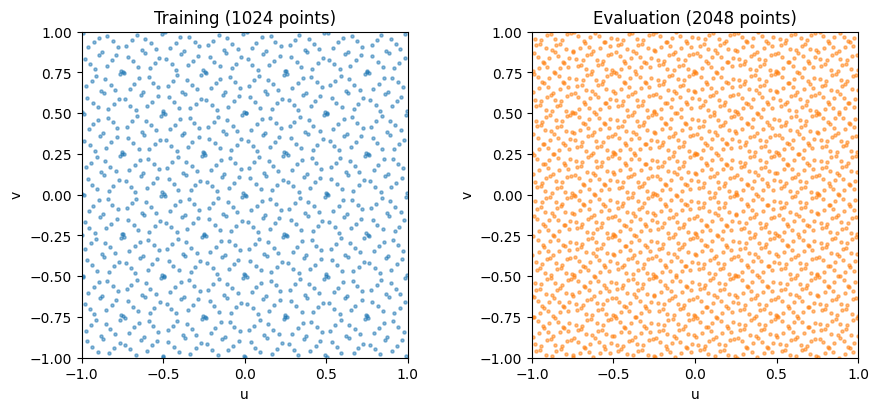

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].scatter(train_x[:, 0].cpu(), train_x[:, 1].cpu(), s=5, alpha=0.5)
axes[0].set(
    title=f"Training ({TRAIN_SAMPLES} points)",
    xlabel="u",
    ylabel="v",
    xlim=(-1, 1),
    ylim=(-1, 1),
    aspect="equal",
)
axes[1].scatter(
    eval_x[:, 0].cpu(), eval_x[:, 1].cpu(), s=5, alpha=0.5, color="tab:orange"
)
axes[1].set(
    title=f"Evaluation ({EVAL_SAMPLES} points)",
    xlabel="u",
    ylabel="v",
    xlim=(-1, 1),
    ylim=(-1, 1),
    aspect="equal",
)
plt.show()


## 4. Model


In [6]:
def build_model(degree):
    """Build the two-coordinate architecture used by the toy experiment."""
    return OrPoNet(
        basis_configs=[
            {"type": "chebyshev", "degree": degree, "constant_channels": 2},
            {"type": "chebyshev", "degree": degree, "constant_channels": 2},
        ],
        data_domain_lb=[-1, -1],
        data_domain_ub=[1, 1],
        training_domain_lb=[-1, -1],
        training_domain_ub=[1, 1],
        neuron_copies=1,
        coeff_init_std=0.1,
        normalize_basis=False,
        dtype=DTYPE,
    ).to(DEVICE)


## 5. Training


In [7]:
ADAM_EPOCHS = 400


models = {}
histories = {}
for name, example in examples.items():
    torch.manual_seed(SEED)
    model = build_model(example["degree"])
    train_y = example["function"](train_x)
    eval_y = example["function"](eval_x)
    trainer = Trainer(model, (train_x, train_y), (eval_x, eval_y), selection=None)
    adam = torch.optim.Adam(model.parameters(), lr=0.001)
    lbfgs = torch.optim.LBFGS(
        model.parameters(),
        lr=1.0,
        max_iter=100,
        history_size=100,
        tolerance_grad=1e-14,
        tolerance_change=1e-14,
        line_search_fn="strong_wolfe",
    )
    print(f"Training {example['label']} (degree {example['degree']})", flush=True)
    trainer.record_initial()
    trainer.fit(adam, epochs=ADAM_EPOCHS, batch_size=128, log_every=100)
    trainer.fit_lbfgs(lbfgs, steps=40, log_every=10)
    histories[name] = trainer.history
    models[name] = model


Training Polynomial (degree 4)


adam 1: validation MSE=2.054e+00


adam 100: validation MSE=2.585e-02


adam 200: validation MSE=1.494e-03


adam 300: validation MSE=2.095e-04


adam 400: validation MSE=4.243e-05


... (20 outputs left out)

lbfgs 10: validation MSE=1.217e-07


lbfgs 20: validation MSE=1.177e-07


lbfgs 30: validation MSE=1.153e-07


lbfgs 40: validation MSE=1.138e-07


## 6. Learning curves


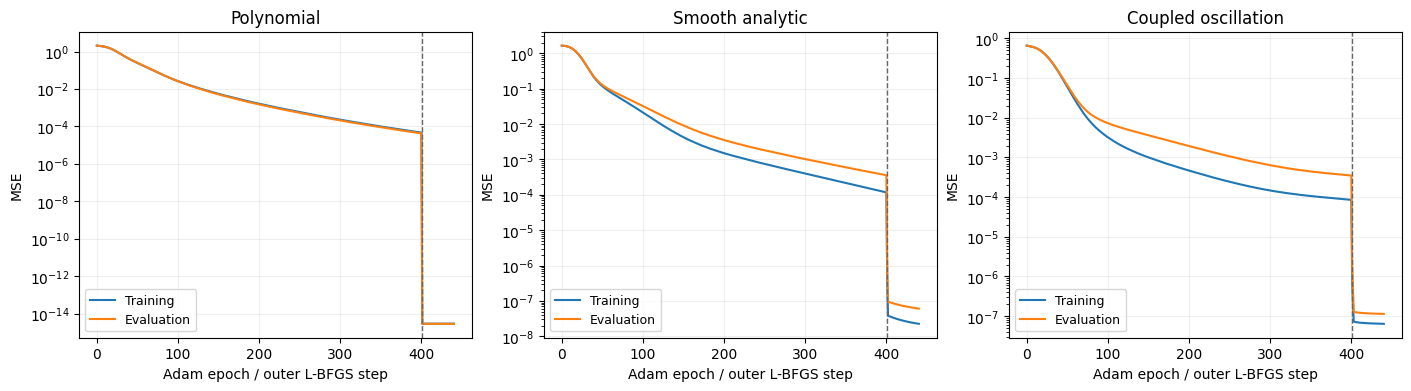

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
for ax, (name, example) in zip(axes, examples.items()):
    history = histories[name]
    ax.semilogy(
        history["update"],
        history["train_mse"].clip(lower=1e-18),
        label="Training",
        linewidth=1.5,
    )
    ax.semilogy(
        history["update"],
        history["validation_mse"].clip(lower=1e-18),
        label="Evaluation",
        linewidth=1.5,
    )
    ax.axvline(ADAM_EPOCHS + 0.5, color="0.4", linestyle="--", linewidth=1)
    ax.set(
        title=example["label"], xlabel="Adam epoch / outer L-BFGS step", ylabel="MSE"
    )
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
plt.show()


## 7. Predictions and errors


In [9]:
grid_results = {}
with torch.no_grad():
    for name, example in examples.items():
        model = models[name]
        model.eval()
        reference = example["function"](grid_x)
        prediction = model(grid_x)
        grid_results[name] = {
            "reference": reference.reshape(GRID_SIZE, GRID_SIZE).cpu(),
            "prediction": prediction.reshape(GRID_SIZE, GRID_SIZE).cpu(),
            "absolute_error": (prediction - reference)
            .abs()
            .reshape(GRID_SIZE, GRID_SIZE)
            .cpu(),
        }


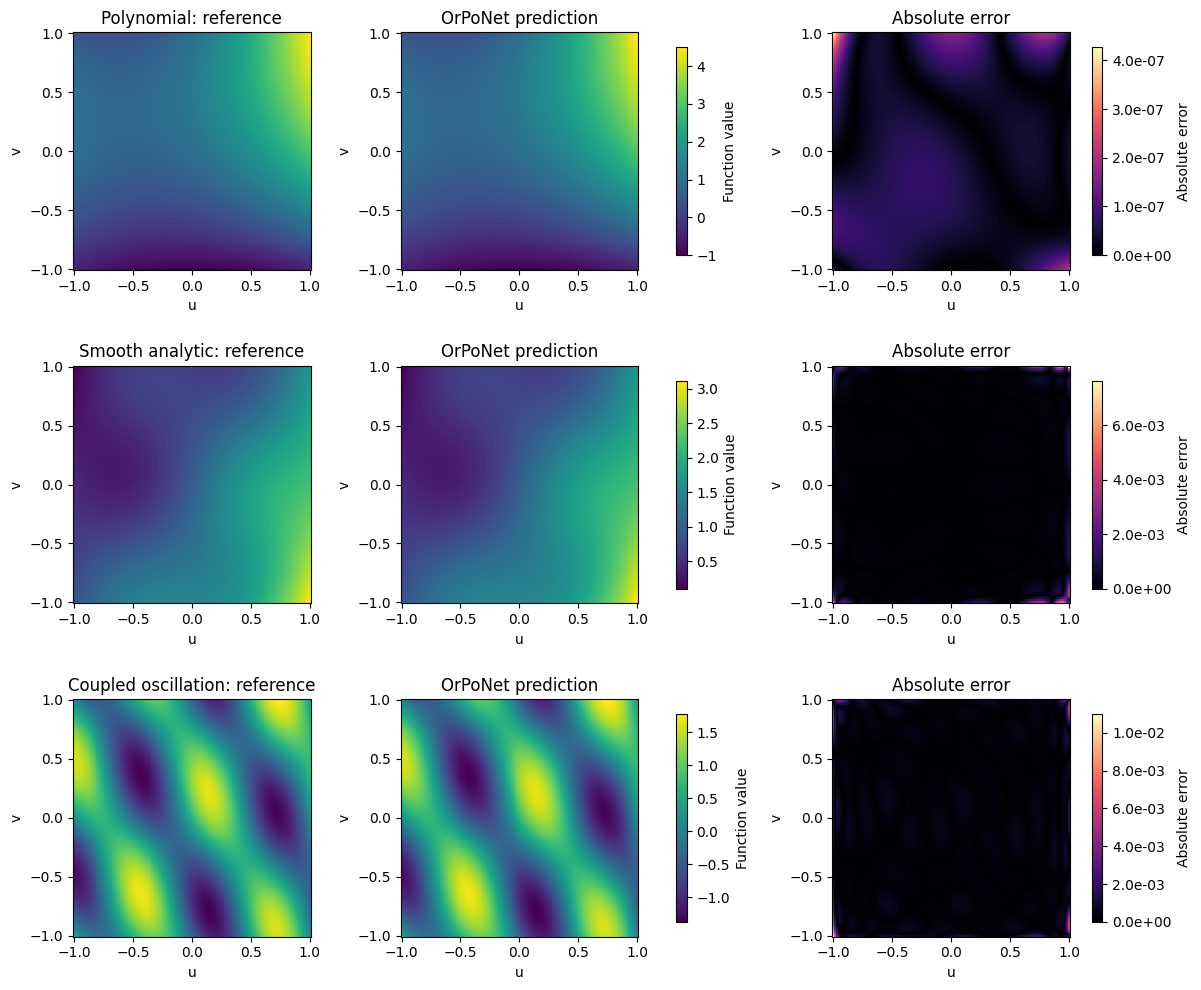

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10), constrained_layout=True)
for row, (name, example) in enumerate(examples.items()):
    fields = grid_results[name]
    lower = min(fields["reference"].min().item(), fields["prediction"].min().item())
    upper = max(fields["reference"].max().item(), fields["prediction"].max().item())
    reference_image = axes[row, 0].pcolormesh(
        grid_u.cpu(),
        grid_v.cpu(),
        fields["reference"],
        shading="auto",
        cmap="viridis",
        vmin=lower,
        vmax=upper,
    )
    prediction_image = axes[row, 1].pcolormesh(
        grid_u.cpu(),
        grid_v.cpu(),
        fields["prediction"],
        shading="auto",
        cmap="viridis",
        vmin=lower,
        vmax=upper,
    )
    error_image = axes[row, 2].pcolormesh(
        grid_u.cpu(),
        grid_v.cpu(),
        fields["absolute_error"],
        shading="auto",
        cmap="magma",
        vmin=0,
        vmax=max(fields["absolute_error"].max().item(), 1e-15),
    )
    axes[row, 0].set_title(f"{example['label']}: reference")
    axes[row, 1].set_title("OrPoNet prediction")
    axes[row, 2].set_title("Absolute error")
    for ax in axes[row]:
        ax.set(xlabel="u", ylabel="v", aspect="equal")
    fig.colorbar(reference_image, ax=axes[row, :2], shrink=0.8, label="Function value")
    fig.colorbar(
        error_image, ax=axes[row, 2], shrink=0.8, label="Absolute error", format="%.1e"
    )
plt.show()
